# Notebook 02c: Entrenamiento LoRA con dataset v3

---
### Objetivo
Mismo diseño experimental que los notebooks 02 y 02b (**solo cambia el rango `r`**, con $\alpha = 2r$; mismo prompt, learning rate, épocas, batch, semilla y GPU T4), ahora sobre `datos/entrenamiento/train_v3.jsonl`.

| | Config 1 | Config 2 |
|---|---|---|
| `r` | 8 | 32 |
| `lora_alpha` | 16 | 64 |
| `target_modules` | q,k,v,o,gate,up,down | q,k,v,o,gate,up,down |
| learning rate | 2e-4 | 2e-4 |
| épocas | 2 | 2 |
| batch efectivo | 16 (2 × 8 acumulación) | 16 (2 × 8 acumulación) |

### Por qué hay un dataset v3
Con v2 el mejor adapter (r8) llegó a **EX 0.520**, todavía por debajo del modelo base (**0.747**). Comparando pregunta por pregunta, el adapter rompe 8 preguntas que el base acertaba y arregla solo 1:

- **Alias `T1`/`T2`/`T3` de Spider**: el modelo los usa y confunde las tablas (val_14, val_16, val_29, val_38).
- **Sin funciones de fecha**: Spider no tiene aritmética de fechas, así que el adapter "olvida" `TIMESTAMPDIFF` y calcula `2026 - fecha_nac` (val_20, val_40).
- **JOIN y GROUP BY más pobres** (val_12, val_34).

`src/generar_v3.py` construye v3:
1. En los 2,429 pares de Spider, `T1`/`T2`/... se reemplazan por alias derivados del nombre de la tabla (`student_course` → `sc`); 784 consultas reescritas, todas re-ejecutadas en MySQL.
2. **460 pares propios sobre 12 esquemas propios** (`datos/esquemas_propios/`), escritos con ayuda de un LLM: nombres en español, inglés y abreviados, con `COMMENT`, y consultas MySQL con fechas, `WITH`, funciones de ventana y subconsultas (205 difíciles). Cada par se ejecutó en MySQL 8.4.10 sobre la base poblada con datos sintéticos. Cada par propio entra 2 veces con distinta redacción de la indicación de columnas (920 ejemplos).

Total: 3,349 ejemplos. Ningún esquema propio coincide con los de validación (`src/chequeo_fuga.py`).

### Cómo usarlo
Una sola corrida entrena ambas configuraciones (~3 h en T4). Al terminar **cada** configuración, su adapter, curva y métricas se suben a GitHub, así una desconexión no hace perder lo ya entrenado.

**Kaggle:** *Accelerator: GPU T4 x2*, *Internet: On*, *Secrets*: `GITHUB_TOKEN`, y **Save & Run All**.

### Hipótesis (escritas ANTES de entrenar)

**H1 — Capacidad vs. tamaño del dataset.** Con `r = 32` el adapter tiene 4× más parámetros entrenables que con `r = 8`. Esperamos que la **loss de entrenamiento** de `r = 32` baje más rápido y termine más baja.

**H2 — Generalización.** Como el dataset es pequeño (~2.4k pares) y los esquemas de la evaluación son distintos a los de entrenamiento, esperamos que la **diferencia en EX sobre la validación propia sea pequeña** (≤ 5 puntos). Si `r = 32` tiene una loss de validación que deja de bajar o sube mientras la de entrenamiento sigue bajando, será señal de sobreajuste y `r = 8` generalizará igual o mejor.

**H3 — Dónde se nota la diferencia.** Si `r = 32` gana, esperamos que la ganancia esté en preguntas **difíciles** (subconsultas, `WITH`, ventanas), que requieren aprender patrones más complejos; en las fáciles ambas deberían ser similares.

**H4 — Costo.** El tiempo de entrenamiento de `r = 32` será solo un poco mayor (≈ +10–20 %), porque el costo lo domina el forward/backward del modelo base, no los adapters.

**H5 — Dataset v3 (escrita antes de entrenar v3).** Los errores de v2 vienen del estilo de Spider (alias `T1`/`T2`, sin funciones de fecha), no de la capacidad del adapter. Con alias legibles y pares MySQL propios (fechas, `WITH`, ventanas), esperamos que el adapter deje de romper las preguntas que el modelo base acierta y que su EX en la validación propia **iguale o supere al baseline (0.747)**; si no lo supera, el problema no es solo de estilo.

In [1]:
# Setup universal (Kaggle, Colab o local)
import os, sys, subprocess
from pathlib import Path

# Reduce la fragmentación de memoria de la GPU (debe ir antes de usar CUDA)
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
# Kaggle da 2 T4: se usa solo una para tener el mismo hardware y batch efectivo que en Colab
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")

EN_KAGGLE = os.path.exists("/kaggle/working")
EN_COLAB = not EN_KAGGLE and ("google.colab" in sys.modules or os.path.exists("/content"))

REPO = "Albu231311/Deep-Proyecto3"
NOMBRE = "erickguerra2"
CORREO = "eagi578@gmail.com"   # el mismo correo ligado a la cuenta de GitHub

if EN_KAGGLE or EN_COLAB:
    ROOT_DIR = Path("/kaggle/working/repo") if EN_KAGGLE else Path("/content/repo")
    if not ROOT_DIR.exists():
        if EN_KAGGLE:
            # Add-ons -> Secrets -> GITHUB_TOKEN (funciona también con "Save & Run All")
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("GITHUB_TOKEN")
        else:
            import getpass
            token = getpass.getpass("GitHub token: ")
        r = subprocess.run(f"git clone -q https://{token}@github.com/{REPO}.git {ROOT_DIR}",
                           shell=True, capture_output=True, text=True)
        if r.returncode != 0:
            raise RuntimeError("No se pudo clonar el repo (¿token correcto y con acceso?): "
                               + r.stderr.replace(token, "***"))
    os.chdir(ROOT_DIR)
    subprocess.run("git pull -q", shell=True, check=True)
    subprocess.run(f'git config user.name "{NOMBRE}"', shell=True)
    subprocess.run(f'git config user.email "{CORREO}"', shell=True)
    subprocess.run("pip install -q -r requirements.txt", shell=True, check=True)
else:

    if Path.cwd().name == "notebooks":
        os.chdir(Path.cwd().parent)
    ROOT_DIR = Path.cwd().resolve()

if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

print(f" Entorno listo. Directorio de trabajo: {os.getcwd()} | Kaggle: {EN_KAGGLE} | Colab: {EN_COLAB}")

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


 Entorno listo. Directorio de trabajo: /kaggle/working/repo | Kaggle: True | Colab: False


## 1. Configuración del experimento

**Único factor que cambia entre configuraciones: `r`** (con `alpha = 2r`).

In [2]:
RS = [8, 32]     # configuraciones a entrenar en esta corrida, en orden
DATASET = "datos/entrenamiento/train_v3.jsonl"
SUFIJO = "_v3"    # se agrega al nombre de cada corrida (adapter_r8, metricas_r8, ...)

MODELO_BASE = "Qwen/Qwen2.5-Coder-1.5B-Instruct"
SEMILLA = 2026
LR = 2e-4
EPOCAS = 2
# Batch 2 x 8: con 4 x 4 los logits (4 x 2048 tokens x 151,936 de vocabulario en fp32,
# ~4.6 GB) no caben en la T4. El batch efectivo sigue siendo 16.
BATCH = 2
ACUMULACION = 8          # batch efectivo = 16
MAX_LEN = 2048           # ejemplos más largos se descartan (se reporta cuántos)
TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

DIR_ADAPTERS = ROOT_DIR / "adapters_experimentos"
DIR_CURVAS = ROOT_DIR / "resultados" / "curvas_loss"
DIR_ADAPTERS.mkdir(parents=True, exist_ok=True)
DIR_CURVAS.mkdir(parents=True, exist_ok=True)

import torch
print(f"Configuraciones: {['r%d' % r for r in RS]} | GPU: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'NINGUNA'}")

Configuraciones: ['r8', 'r32'] | GPU: Tesla T4


## 2. Datos

Se separa ~5 % de las **bases** de entrenamiento (partición por `db_id`, no por pregunta) solo para graficar la loss de validación durante el entrenamiento. La validación propia de 40 preguntas (`datos/validacion/`) no se usa aquí; se evalúa por ejecución en el notebook 03.

In [3]:
import json, random
from collections import Counter

with open(DATASET, encoding="utf-8") as f:
    datos = [json.loads(l) for l in f]

bases = sorted({d["db_id"] for d in datos})
rng = random.Random(SEMILLA)
rng.shuffle(bases)
bases_eval = set(bases[: max(3, len(bases) // 20)])

train_raw = [d for d in datos if d["db_id"] not in bases_eval]
eval_raw = [d for d in datos if d["db_id"] in bases_eval]
print(f"Total: {len(datos)} | train: {len(train_raw)} | eval (loss): {len(eval_raw)} | bases eval: {sorted(bases_eval)}")
print("Niveles train:", Counter(d["nivel"] for d in train_raw))

Total: 3349 | train: 3191 | eval (loss): 158 | bases eval: ['spider_department_store', 'spider_manufactory_1', 'spider_ship_1']
Niveles train: Counter({'media': 1234, 'facil': 1195, 'dificil': 762})


## 3. Tokenización con el prompt oficial y enmascarado del prompt

Se usa **exactamente** el mismo prompt que en `solucion.py` (`src/prompt.py`). Los tokens del prompt (system + esquema + pregunta) llevan `label = -100`, así la loss se calcula **solo sobre la consulta SQL** (y el token de fin `<|im_end|>`, para que aprenda a detenerse).

In [4]:
from transformers import AutoTokenizer
from src.prompt import construir_mensajes

tokenizer = AutoTokenizer.from_pretrained(MODELO_BASE)

def tokenizar(ej):
    mensajes = construir_mensajes(ej["esquema"], ej["pregunta"])
    prompt = tokenizer.apply_chat_template(mensajes, tokenize=False, add_generation_prompt=True)
    completo = tokenizer.apply_chat_template(
        mensajes + [{"role": "assistant", "content": ej["sql"]}], tokenize=False
    )
    assert completo.startswith(prompt)
    ids_prompt = tokenizer(prompt, add_special_tokens=False)["input_ids"]
    ids = tokenizer(completo, add_special_tokens=False)["input_ids"]
    labels = [-100] * len(ids_prompt) + ids[len(ids_prompt):]
    return {"input_ids": ids, "labels": labels}

def preparar(lista):
    salida, largos = [], []
    for ej in lista:
        t = tokenizar(ej)
        largos.append(len(t["input_ids"]))
        if len(t["input_ids"]) <= MAX_LEN:
            salida.append(t)
    return salida, largos

train_tok, largos = preparar(train_raw)
eval_tok, _ = preparar(eval_raw)

import numpy as np
print(f"Tokens por ejemplo: media={np.mean(largos):.0f}, p95={np.percentile(largos, 95):.0f}, max={max(largos)}")
print(f"Descartados por > {MAX_LEN} tokens: {len(train_raw) - len(train_tok)}")
print(f"Ejemplos finales -> train: {len(train_tok)} | eval: {len(eval_tok)}")

# Verificación visual del enmascarado
ej = train_tok[0]
print("\n--- Parte que SÍ entra en la loss ---")
print(tokenizer.decode([t for t, l in zip(ej["input_ids"], ej["labels"]) if l != -100]))

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Tokens por ejemplo: media=823, p95=1682, max=2037
Descartados por > 2048 tokens: 0
Ejemplos finales -> train: 3191 | eval: 158

--- Parte que SÍ entra en la loss ---
SELECT DISTINCT COUNT(DISTINCT paperid) AS cantidad_paperid FROM paper<|im_end|>



## 4. Subida de resultados a GitHub

La máquina de Kaggle/Colab se borra al terminar la sesión, así que cada resultado se sube al repo en cuanto existe (con el usuario configurado en el setup). Después, en la PC: `git pull`.

In [5]:
import re

def subir(rutas, mensaje):
    # git add + commit + push; oculta el token en lo que se imprime
    if not (EN_KAGGLE or EN_COLAB):
        print("[local] no se sube automáticamente:", mensaje)
        return
    def git(cmd):
        r = subprocess.run(cmd, shell=True, capture_output=True, text=True, cwd=ROOT_DIR)
        salida = re.sub(r"https://[^@\s]+@", "https://***@", r.stdout + r.stderr).strip()
        if salida:
            print(salida)
        return r.returncode
    rutas = [str(r) for r in rutas if (ROOT_DIR / r).exists()]
    git("git add " + " ".join(f'"{r}"' for r in rutas))
    if git(f'git commit -q -m "{mensaje}"') != 0:
        print("Nada nuevo que subir.")
        return
    for intento in range(3):
        git("git pull -q --rebase")
        if git("git push -q") == 0:
            print("Push OK:", mensaje)
            return
    print("ERROR en el push:", mensaje)

## 5. Entrenamiento de cada configuración

Para cada `r`: modelo base en `float16` (T4 no soporta bf16) + LoRA (pesos LoRA en `float32` para que la precisión mixta `fp16=True` sea estable), entrenamiento, y **en la misma celda** se guarda el adapter (en `float16`: r=32 en float32 pesaría ~148 MB, más de los 100 MB permitidos), las métricas y la curva de loss, y se suben a GitHub.


Configuración r8_v3: r=8, alpha=16


model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

trainable params: 9,232,384 || all params: 1,552,946,688 || trainable%: 0.5945


Step,Training Loss,Validation Loss
50,0.155690,0.153225
100,0.099457,0.139807
150,0.105619,0.118798
200,0.058293,0.116377
250,0.037553,0.112972
300,0.040533,0.118260
350,0.045858,0.115905
400,0.025879,0.114973



[época 1] adapter guardado en /kaggle/working/repo/adapters_experimentos/adapter_r8_v3_ep1 (18.5 MB)

Tiempo de entrenamiento (r8_v3): 95.3 min
Adapter guardado en /kaggle/working/repo/adapters_experimentos/adapter_r8_v3 (18.5 MB)


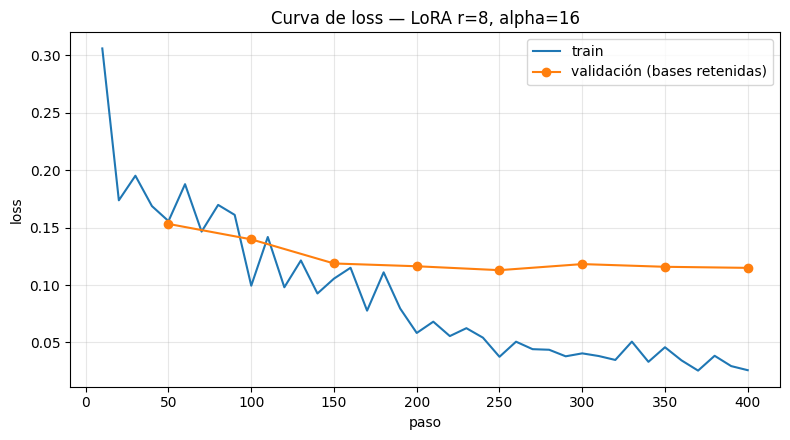

{'config': 'r8_v3', 'dataset': 'datos/entrenamiento/train_v3.jsonl', 'r': 8, 'lora_alpha': 16, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], 'learning_rate': 0.0002, 'epocas': 2, 'batch_efectivo': 16, 'parametros_entrenables': 9232384, 'parametros_totales': 1552946688, 'porcentaje_entrenable': 0.5945074657965335, 'tiempo_entrenamiento_min': 95.28, 'gpu': 'Tesla T4', 'ejemplos_train': 3191, 'ejemplos_eval': 158, 'train_loss_final': 0.02587926983833313, 'eval_loss_final': 0.11497326195240021, 'eval_loss_min': 0.11297153681516647, 'tamano_adapter_mb': 18.5}
Push OK: feat(entrenamiento): adapter LoRA r8_v3 y curvas de loss

Configuración r32_v3: r=32, alpha=64


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

trainable params: 36,929,536 || all params: 1,580,643,840 || trainable%: 2.3364


Step,Training Loss,Validation Loss
50,0.153765,0.141141
100,0.105579,0.135763
150,0.092562,0.115643
200,0.053143,0.105690
250,0.030148,0.108297
300,0.029594,0.102693
350,0.039130,0.101683
400,0.017384,0.101304



[época 1] adapter guardado en /kaggle/working/repo/adapters_experimentos/adapter_r32_v3_ep1 (73.9 MB)

Tiempo de entrenamiento (r32_v3): 96.1 min
Adapter guardado en /kaggle/working/repo/adapters_experimentos/adapter_r32_v3 (73.9 MB)


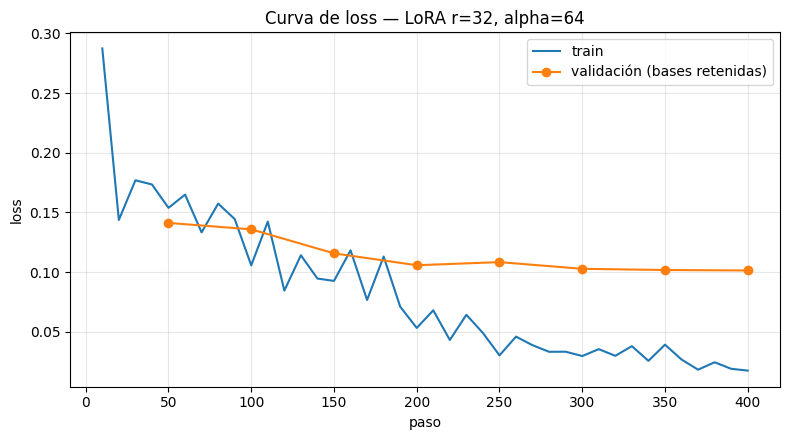

{'config': 'r32_v3', 'dataset': 'datos/entrenamiento/train_v3.jsonl', 'r': 32, 'lora_alpha': 64, 'target_modules': ['q_proj', 'k_proj', 'v_proj', 'o_proj', 'gate_proj', 'up_proj', 'down_proj'], 'learning_rate': 0.0002, 'epocas': 2, 'batch_efectivo': 16, 'parametros_entrenables': 36929536, 'parametros_totales': 1580643840, 'porcentaje_entrenable': 2.336360353006532, 'tiempo_entrenamiento_min': 96.14, 'gpu': 'Tesla T4', 'ejemplos_train': 3191, 'ejemplos_eval': 158, 'train_loss_final': 0.01738446354866028, 'eval_loss_final': 0.10130419582128525, 'eval_loss_min': 0.10130419582128525, 'tamano_adapter_mb': 73.9}
remote: warning: See https://gh.io/lfs for more information.        
remote: warning: File adapters_experimentos/adapter_r32_v3/adapter_model.safetensors is 70.49 MB; this is larger than GitHub's recommended maximum file size of 50.00 MB        
remote: warning: File adapters_experimentos/adapter_r32_v3_ep1/adapter_model.safetensors is 70.49 MB; this is larger than GitHub's recommend

In [6]:
import gc, time, inspect
import matplotlib.pyplot as plt
from safetensors.torch import load_file, save_file
from transformers import AutoModelForCausalLM, Trainer, TrainerCallback, TrainingArguments, set_seed
from peft import LoraConfig, get_peft_model
from src.compat import parchear_torchao

parchear_torchao()   # Kaggle/Colab traen un torchao viejo que rompe peft (ver src/compat.py)

def collate(batch):
    # Padding a la derecha; las posiciones de padding no cuentan en la loss
    largo = max(len(b["input_ids"]) for b in batch)
    pad = tokenizer.pad_token_id
    input_ids = [b["input_ids"] + [pad] * (largo - len(b["input_ids"])) for b in batch]
    labels = [b["labels"] + [-100] * (largo - len(b["labels"])) for b in batch]
    mask = [[1] * len(b["input_ids"]) + [0] * (largo - len(b["input_ids"])) for b in batch]
    return {
        "input_ids": torch.tensor(input_ids),
        "labels": torch.tensor(labels),
        "attention_mask": torch.tensor(mask),
    }

# Agrupar ejemplos de largo parecido (menos padding = más rápido).
# transformers v5 renombró group_by_length -> train_sampling_strategy
if "train_sampling_strategy" in inspect.signature(TrainingArguments).parameters:
    AGRUPAR = {"train_sampling_strategy": "group_by_length"}
else:
    AGRUPAR = {"group_by_length": True}


def guardar_adapter(modelo, destino):
    # Adapter en float16: r=32 en float32 pesaría ~148 MB (> 100 MB permitidos)
    modelo.save_pretrained(destino)
    archivo = Path(destino) / "adapter_model.safetensors"
    pesos = load_file(archivo)
    save_file({k: v.half() for k, v in pesos.items()}, archivo, metadata={"format": "pt"})
    return sum(f.stat().st_size for f in Path(destino).glob("*")) / 1e6


class AdapterPorEpoca(TrainerCallback):
    # Guarda el adapter al final de cada época (salvo la última, que es el adapter final),
    # para comparar en EX si conviene entrenar 1 o 2 épocas sin entrenar dos veces
    def __init__(self, nombre_run):
        self.nombre_run = nombre_run
        self.rutas = []

    def on_epoch_end(self, args, state, control, model=None, **kwargs):
        epoca = round(state.epoch)
        if epoca < args.num_train_epochs:
            destino = DIR_ADAPTERS / f"adapter_{self.nombre_run}_ep{epoca}"
            mb = guardar_adapter(model, destino)
            self.rutas.append(f"adapters_experimentos/{destino.name}")
            print(f"\n[época {epoca}] adapter guardado en {destino} ({mb:.1f} MB)")


def entrenar_config(R):
    nombre_run = f"r{R}{SUFIJO}"
    alpha = 2 * R
    print(f"\n{'=' * 60}\nConfiguración {nombre_run}: r={R}, alpha={alpha}\n{'=' * 60}")
    set_seed(SEMILLA)

    # Modelo + LoRA
    modelo = AutoModelForCausalLM.from_pretrained(MODELO_BASE, dtype=torch.float16).to("cuda")
    modelo.config.use_cache = False
    modelo.gradient_checkpointing_enable(gradient_checkpointing_kwargs={"use_reentrant": False})
    modelo.enable_input_require_grads()
    modelo = get_peft_model(modelo, LoraConfig(
        r=R,
        lora_alpha=alpha,
        lora_dropout=0.05,
        target_modules=TARGET_MODULES,
        bias="none",
        task_type="CAUSAL_LM",
    ))
    for p in modelo.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    modelo.print_trainable_parameters()
    entrenables = sum(p.numel() for p in modelo.parameters() if p.requires_grad)
    totales = sum(p.numel() for p in modelo.parameters())

    # Entrenamiento
    args = TrainingArguments(
        output_dir=str(ROOT_DIR / "checkpoints" / nombre_run),
        per_device_train_batch_size=BATCH,
        per_device_eval_batch_size=1,
        gradient_accumulation_steps=ACUMULACION,
        num_train_epochs=EPOCAS,
        learning_rate=LR,
        lr_scheduler_type="cosine",
        warmup_steps=10,         # ~3 % de los ~296 pasos
        fp16=True,
        logging_steps=10,
        eval_strategy="steps",
        eval_steps=50,
        save_strategy="no",
        report_to="none",
        seed=SEMILLA,
        remove_unused_columns=False,
        **AGRUPAR,
    )
    por_epoca = AdapterPorEpoca(nombre_run)
    trainer = Trainer(model=modelo, args=args, train_dataset=train_tok,
                      eval_dataset=eval_tok, data_collator=collate, callbacks=[por_epoca])
    inicio = time.time()
    trainer.train()
    tiempo_min = (time.time() - inicio) / 60
    print(f"\nTiempo de entrenamiento ({nombre_run}): {tiempo_min:.1f} min")

    # Adapter final (float16)
    dir_adapter = DIR_ADAPTERS / f"adapter_{nombre_run}"
    tam_mb = guardar_adapter(modelo, dir_adapter)
    print(f"Adapter guardado en {dir_adapter} ({tam_mb:.1f} MB)")

    # Métricas e historial de loss
    historial = trainer.state.log_history
    train_pts = [(h["step"], h["loss"]) for h in historial if "loss" in h]
    eval_pts = [(h["step"], h["eval_loss"]) for h in historial if "eval_loss" in h]
    metricas = {
        "config": nombre_run,
        "dataset": DATASET,
        "r": R,
        "lora_alpha": alpha,
        "target_modules": TARGET_MODULES,
        "learning_rate": LR,
        "epocas": EPOCAS,
        "batch_efectivo": BATCH * ACUMULACION,
        "parametros_entrenables": entrenables,
        "parametros_totales": totales,
        "porcentaje_entrenable": 100 * entrenables / totales,
        "tiempo_entrenamiento_min": round(tiempo_min, 2),
        "gpu": torch.cuda.get_device_name(0),
        "ejemplos_train": len(train_tok),
        "ejemplos_eval": len(eval_tok),
        "train_loss_final": train_pts[-1][1],
        "eval_loss_final": eval_pts[-1][1] if eval_pts else None,
        "eval_loss_min": min(e for _, e in eval_pts) if eval_pts else None,
        "tamano_adapter_mb": round(tam_mb, 1),
        "historial": historial,
    }
    with open(DIR_CURVAS / f"metricas_{nombre_run}.json", "w", encoding="utf-8") as f:
        json.dump(metricas, f, indent=2, ensure_ascii=False)

    plt.figure(figsize=(8, 4.5))
    plt.plot(*zip(*train_pts), label="train")
    if eval_pts:
        plt.plot(*zip(*eval_pts), "o-", label="validación (bases retenidas)")
    plt.xlabel("paso")
    plt.ylabel("loss")
    plt.title(f"Curva de loss — LoRA r={R}, alpha={alpha}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(DIR_CURVAS / f"loss_{nombre_run}.png", dpi=150)
    plt.show()
    print({k: v for k, v in metricas.items() if k != "historial"})

    # Subir de inmediato: si la sesión se cae después, esto ya queda a salvo
    subir(
        [f"adapters_experimentos/adapter_{nombre_run}",
         f"resultados/curvas_loss/loss_{nombre_run}.png",
         f"resultados/curvas_loss/metricas_{nombre_run}.json"] + por_epoca.rutas,
        f"feat(entrenamiento): adapter LoRA {nombre_run} y curvas de loss",
    )

    # Liberar la GPU para la siguiente configuración
    del trainer, modelo, por_epoca
    gc.collect()
    torch.cuda.empty_cache()


for R in RS:
    entrenar_config(R)

## 6. Comparación de ambas configuraciones

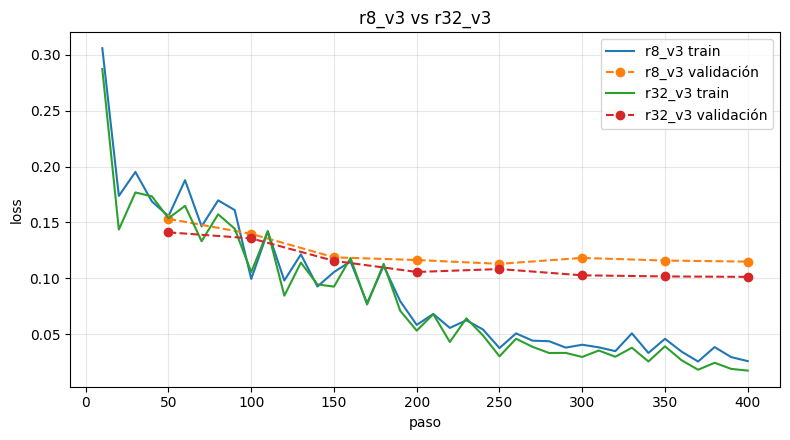

Push OK: docs(entrenamiento): comparación de curvas de loss r8_v3 vs r32_v3


,config,parametros_entrenables,porcentaje_entrenable,tiempo_entrenamiento_min,train_loss_final,eval_loss_final,eval_loss_min,tamano_adapter_mb
0,r8_v3,9232384,0.594507,95.28,0.025879,0.114973,0.112972,18.5
1,r32_v3,36929536,2.336360,96.14,0.017384,0.101304,0.101304,73.9


In [7]:
import pandas as pd

filas, hay_curvas = [], False
plt.figure(figsize=(8, 4.5))
nombres = [f"r{r}{SUFIJO}" for r in RS]
for nombre in nombres:
    p = DIR_CURVAS / f"metricas_{nombre}.json"
    if not p.exists():
        continue
    m = json.load(open(p, encoding="utf-8"))
    filas.append({k: m.get(k) for k in ["config", "parametros_entrenables", "porcentaje_entrenable",
                                        "tiempo_entrenamiento_min", "train_loss_final", "eval_loss_final",
                                        "eval_loss_min", "tamano_adapter_mb"]})
    h = m["historial"]
    plt.plot([x["step"] for x in h if "loss" in x], [x["loss"] for x in h if "loss" in x], label=f"{nombre} train")
    plt.plot([x["step"] for x in h if "eval_loss" in x], [x["eval_loss"] for x in h if "eval_loss" in x],
             "o--", label=f"{nombre} validación")
    hay_curvas = True

if len(filas) > 1:
    archivo = f"comparacion_{'_'.join(nombres)}.png"
    plt.xlabel("paso"); plt.ylabel("loss"); plt.title(" vs ".join(nombres))
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(DIR_CURVAS / archivo, dpi=150)
    plt.show()
    subir([f"resultados/curvas_loss/{archivo}"],
          f"docs(entrenamiento): comparación de curvas de loss {' vs '.join(nombres)}")
pd.DataFrame(filas)

## 7. Copiar el mejor adapter a `adapter/`

El mejor se elige por **EX en la validación propia** (notebook 03), no por la loss. Esto se puede hacer también en la PC (copiar los dos archivos y hacer commit).

In [8]:
import shutil

MEJOR = None   # <-- "r8" o "r32", después de evaluar en el notebook 03

if MEJOR:
    origen = DIR_ADAPTERS / f"adapter_{MEJOR}"
    destino = ROOT_DIR / "adapter"
    destino.mkdir(exist_ok=True)
    for nombre in ["adapter_config.json", "adapter_model.safetensors"]:
        shutil.copy(origen / nombre, destino / nombre)
    print(sorted(p.name for p in destino.iterdir()))
    subir(["adapter/adapter_config.json", "adapter/adapter_model.safetensors"],
          f"feat(entrenamiento): adapter final ({MEJOR}) en adapter/")